# Plotting the Data

This notebook has been designed to create some nice plots to explore the data. This will allow you to see what did you start with and what is the output now.

All plots below use **one date** (one interim file, the raw file it was made from, and the matching Zarr time step) and **the same extent** (the area that holds valid interim data).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr


## function to find the root of the repository, which is assumed to contain a "data" directory
def find_repo_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not find a repository containing data/")


### I am using Metref as the default variable to plot, but you can change it to any other variable in the dataset.
def select_plot_variable(ds: xr.Dataset) -> str:
    preferred = ["METREF", "metref"]
    for name in preferred:
        if name in ds.data_vars:
            return name
    numeric = [name for name, da in ds.data_vars.items() if da.dtype.kind in "iuf"]
    if not numeric:
        raise ValueError("Dataset has no numeric data variable to plot")
    return numeric[0]


def latlon_names(da: xr.DataArray) -> tuple[str, str]:
    lat = next(n for n in ("lat", "latitude", "y") if n in da.dims)
    lon = next(n for n in ("lon", "longitude", "x") if n in da.dims)
    return lat, lon


def get_2d(ds: xr.Dataset, time=None) -> xr.DataArray:
    """Plot variable as a loaded 2D (lat, lon) array. time=None -> first step, else nearest step."""
    da = ds[select_plot_variable(ds)]
    if "time" in da.dims:
        da = da.isel(time=0) if time is None else da.sel(time=time, method="nearest")
    lat, lon = latlon_names(da)
    return da.drop_vars("time", errors="ignore").transpose(lat, lon).load()


def valid_bbox(da: xr.DataArray, pad: float = 0.0) -> tuple[float, float, float, float]:
    """(lon_min, lon_max, lat_min, lat_max) of the cells that are not NaN."""
    lat, lon = latlon_names(da)
    ok = da.notnull().values
    if not ok.any():
        raise ValueError("Array has no valid cells")
    lats, lons = da[lat].values[ok.any(axis=1)], da[lon].values[ok.any(axis=0)]
    return lons.min() - pad, lons.max() + pad, lats.min() - pad, lats.max() + pad


def crop(da: xr.DataArray, bbox) -> xr.DataArray:
    lon0, lon1, lat0, lat1 = bbox
    lat, lon = latlon_names(da)
    da = da.sortby(lat).sortby(lon)
    return da.sel({lat: slice(lat0, lat1), lon: slice(lon0, lon1)})


def grid_report(da: xr.DataArray, label: str) -> None:
    """Print grid extent vs. extent of valid data - makes an oversized target grid obvious."""
    lat, lon = latlon_names(da)
    g = (float(da[lon].min()), float(da[lon].max()), float(da[lat].min()), float(da[lat].max()))
    v = valid_bbox(da)
    area = lambda b: (b[1] - b[0]) * (b[3] - b[2])
    share = 100 * area(v) / area(g) if area(g) else 100
    print(f"{label}: grid {da.shape}, lon {g[0]:.2f}..{g[1]:.2f}, lat {g[2]:.2f}..{g[3]:.2f} | "
          f"valid data lon {v[0]:.2f}..{v[1]:.2f}, lat {v[2]:.2f}..{v[3]:.2f} ({share:.0f}% of grid)")
    if share < 50:
        print("   WARNING: valid data fills less than half of the grid -> the grid is larger than the clipped area")


### Quick snapshot plot of a 2D field. By default it zooms to the valid data, so no empty margins.
def plot_snapshot(da: xr.DataArray, title: str, cmap: str = "viridis", bbox=None, ax=None, **kwargs):
    grid_report(da, title)
    bbox = bbox or valid_bbox(da, pad=0.1)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5))
    crop(da, bbox).plot(ax=ax, robust=True, cmap=cmap, **kwargs)
    ax.set_aspect("equal", adjustable="box")  ## aspect ratio
    ax.set_title(title)
    return ax

REPO_ROOT = find_repo_root()
DATA_ROOT = REPO_ROOT / "data"

## Pick one date

In [2]:
raw_files = sorted((DATA_ROOT / "raw").rglob("*.nc"))
interim_files = sorted((DATA_ROOT / "interim").rglob("*.nc"))
zarr_stores = sorted(
    path for path in (DATA_ROOT / "zarr").iterdir()
    if path.is_dir() and ((path / "zarr.json").exists() or (path / ".zgroup").exists())
)
assert raw_files, "No raw NetCDF files found"
assert interim_files, "No interim NetCDF files found"
assert zarr_stores, "No Zarr stores found"

## Pick ONE interim file, then the raw file it was made from -> same date in every panel.
INTERIM_IDX = 0
interim_path = interim_files[INTERIM_IDX]
raw_name = interim_path.name.replace("_processed.nc", ".nc")
raw_path = next((p for p in raw_files if p.name == raw_name), None)
assert raw_path is not None, f"No raw file named {raw_name}"
zarr_path = zarr_stores[0]

with xr.open_dataset(interim_path, decode_cf=True, mask_and_scale=True) as interim_ds:
    interim_da = get_2d(interim_ds)
    interim_time = np.atleast_1d(interim_ds.time.values)[0]

## The common extent = area that holds valid interim data (+0.1 degree margin)
AOI = valid_bbox(interim_da, pad=0.1)
print(f"Date: {np.datetime_as_string(interim_time, unit='h')}")
print(f"Common extent: lon {AOI[0]:.2f}..{AOI[1]:.2f}, lat {AOI[2]:.2f}..{AOI[3]:.2f}")

Date: 2010-01-01T00
Common extent: lon -17.35..-11.15, lat 12.15..16.85


## Raw NetCDF

Raw: NETCDF4_LSASAF_MSG_METREF_MSG-Disk_201001010000.nc: grid (95, 125), lon -17.35..-11.15, lat 12.15..16.85 | valid data lon -17.35..-11.15, lat 12.15..16.85 (100% of grid)


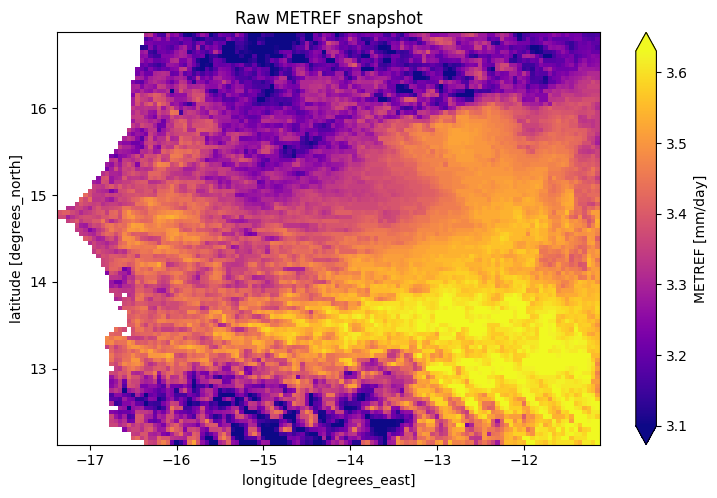

In [3]:
with xr.open_dataset(raw_path, decode_cf=True, mask_and_scale=True) as raw_ds:
    raw_da = crop(get_2d(raw_ds), AOI)   ## the raw file is the full MSG disk -> cut to the common extent

plot_snapshot(raw_da, f"Raw: {raw_path.name}", cmap="plasma", bbox=AOI)
plt.tight_layout()
plt.title("Raw METREF snapshot")
plt.show()

### Raw - full disk

The whole MSG disk, with the common extent used in the plots above marked in red.

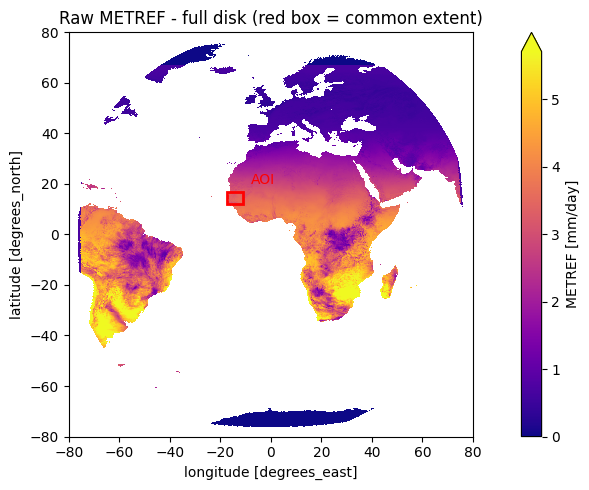

In [4]:
from matplotlib.patches import Rectangle

with xr.open_dataset(raw_path, decode_cf=True, mask_and_scale=True) as raw_full_ds:
    raw_full = get_2d(raw_full_ds)

fig, ax = plt.subplots(figsize=(10, 5))
raw_full.plot(ax=ax, robust=True, cmap="plasma")
ax.add_patch(Rectangle((AOI[0], AOI[2]), AOI[1] - AOI[0], AOI[3] - AOI[2],
                       fill=False, edgecolor="red", lw=2))
ax.annotate("AOI", (AOI[1], AOI[3]), xytext=(6, 6), textcoords="offset points", color="red")
ax.set_aspect("equal", adjustable="box")
ax.set_title("Raw METREF - full disk (red box = common extent)")
plt.tight_layout()
plt.show()

del raw_full   ## free memory

## Interim NetCDF

Interim: NETCDF4_LSASAF_MSG_METREF_MSG-Disk_201001010000_processed.nc: grid (91, 121), lon -17.25..-11.25, lat 12.25..16.75 | valid data lon -17.25..-11.25, lat 12.25..16.75 (100% of grid)


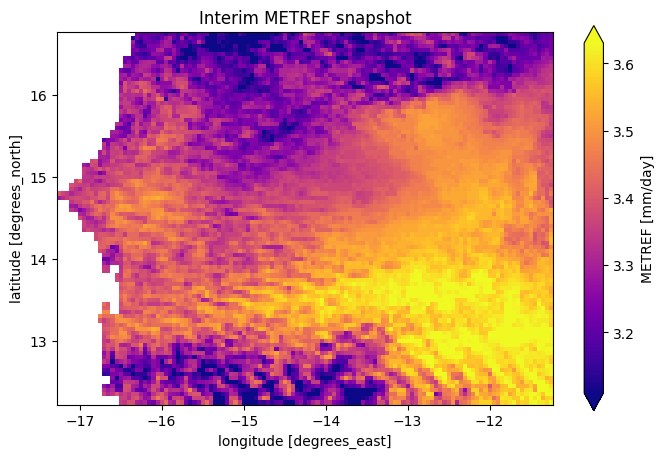

In [5]:
plot_snapshot(interim_da, f"Interim: {interim_path.name}", cmap="plasma", bbox=AOI)
plt.title("Interim METREF snapshot")
plt.show()

## Zarr

Zarr time step used: 2010-01-01T00
Zarr: metref_cube.zarr: grid (91, 121), lon -17.25..-11.25, lat 12.25..16.75 | valid data lon -17.25..-11.25, lat 12.25..16.75 (100% of grid)


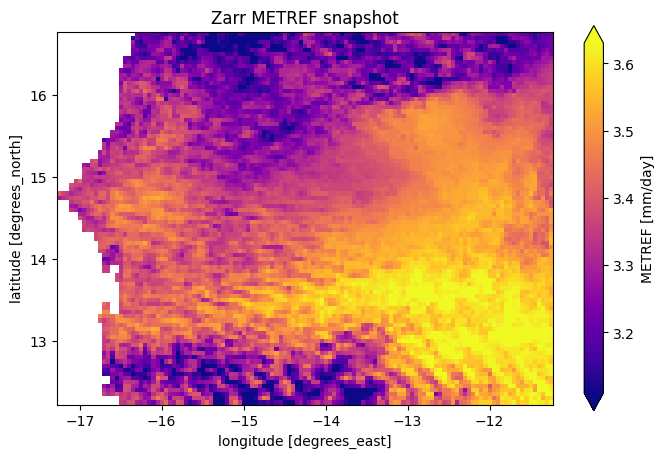

In [8]:
with xr.open_zarr(zarr_path, consolidated=None) as zarr_ds:
    zarr_time = zarr_ds.time.sel(time=interim_time, method="nearest").values   ## same date as the interim file
    zarr_da = get_2d(zarr_ds, time=zarr_time)
print(f"Zarr time step used: {np.datetime_as_string(zarr_time, unit='h')}")

plot_snapshot(zarr_da, f"Zarr: {zarr_path.name}", cmap="plasma",bbox=AOI)
plt.title("Zarr METREF snapshot")
plt.show()

## Raw versus interim versus Zarr (same date, same extent, same colour scale)

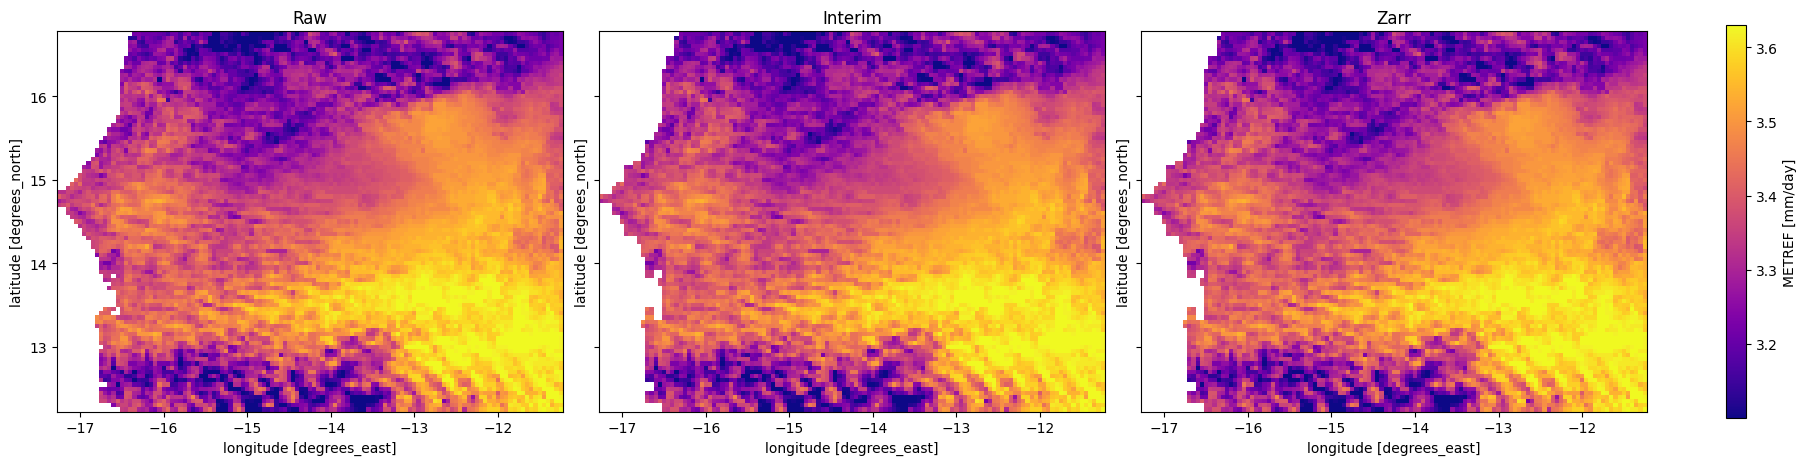

In [9]:
panels = [("Raw", raw_da, "plasma"), ("Interim", interim_da, "plasma"), ("Zarr", zarr_da, "plasma")]
units = interim_da.attrs.get("units", "")

all_values = np.concatenate([crop(da, AOI).values.ravel() for _, da, _ in panels])
vmin, vmax = np.nanpercentile(all_values, [2, 98])

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True, sharex=True, sharey=True)
for axis, (label, da, cmap) in zip(axes, panels):
    mesh = crop(da, AOI).plot(ax=axis, vmin=vmin, vmax=vmax, cmap=cmap, add_colorbar=False)
    axis.set_title(label)
    axis.set_aspect("equal", adjustable="box")
fig.colorbar(mesh, ax=axes, shrink=0.8, label=f"METREF [{units}]")
plt.show()

### After Remap

Interim - Raw for the same grid.

The raw file (0.05 deg grid, full MSG disk) and the interim file (clipped + remapped) do not share grid nodes,
so the raw values first have to be put on the interim grid:

* `"nearest"` - take the raw pixel closest to each interim cell (shows the effect of the bilinear remap),
* `"linear"` - interpolate the raw field bilinearly (what `cdo remapbil` does, so the difference should be close to zero).

cells valid in both: 9972 | valid in raw but NaN after remap: 93 | NaN in raw but valid after remap: 0
bias 0.0000 | RMSE 0.0000 | max |diff| 0.0000 mm/day


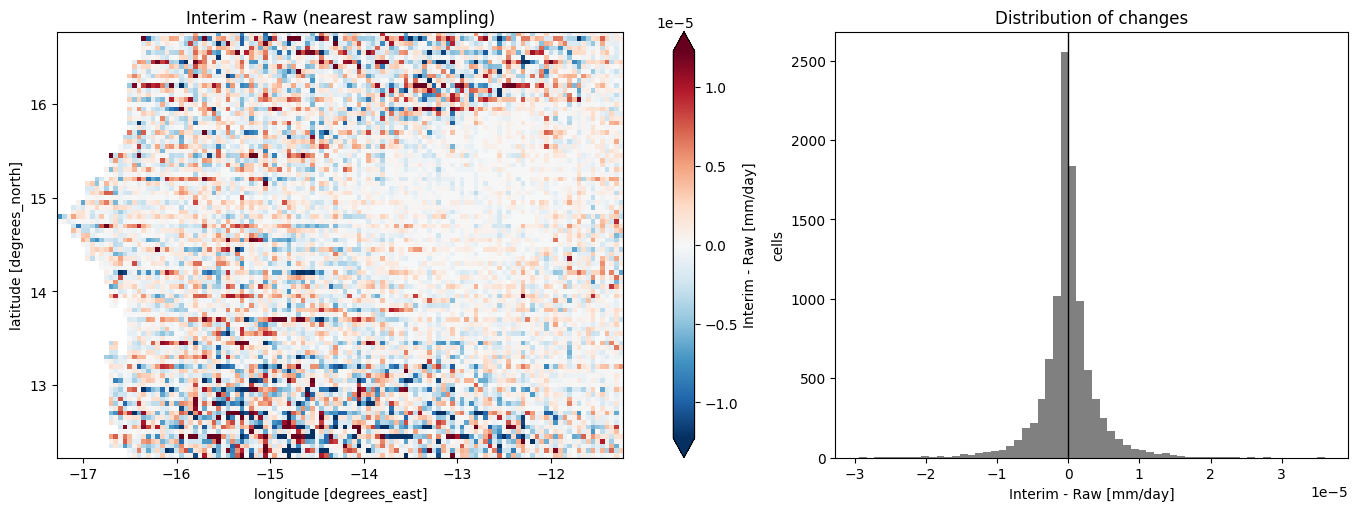

In [10]:
DIFF_METHOD = "nearest"   # "nearest" or "linear"

interim_aoi = crop(interim_da, AOI)
ilat, ilon = latlon_names(interim_aoi)
rlat, rlon = latlon_names(raw_da)
target = {rlat: interim_aoi[ilat].values, rlon: interim_aoi[ilon].values}

if DIFF_METHOD == "nearest":
    raw_on_interim = raw_da.reindex(target, method="nearest", tolerance=0.05)
else:
    raw_on_interim = raw_da.interp(target, method="linear")
if (rlat, rlon) != (ilat, ilon):
    raw_on_interim = raw_on_interim.rename({rlat: ilat, rlon: ilon})

diff = interim_aoi - raw_on_interim          ## interim - raw

lost = int((raw_on_interim.notnull() & interim_aoi.isnull()).sum())
gained = int((raw_on_interim.isnull() & interim_aoi.notnull()).sum())
print(f"cells valid in both: {int(diff.notnull().sum())} | valid in raw but NaN after remap: {lost} | NaN in raw but valid after remap: {gained}")
print(f"bias {float(diff.mean()):.4f} | RMSE {float(np.sqrt((diff ** 2).mean())):.4f} | max |diff| {float(abs(diff).max()):.4f} {units}")

limit = float(np.nanpercentile(abs(diff.values), 98)) or 1e-6      ## symmetric colour scale around 0
fig, (ax_map, ax_hist) = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True,
                                      gridspec_kw={"width_ratios": [1.3, 1]})
diff.plot(ax=ax_map, cmap="RdBu_r", vmin=-limit, vmax=limit, cbar_kwargs={"label": f"Interim - Raw [{units}]"})
ax_map.set_aspect("equal", adjustable="box")
ax_map.set_title(f"Interim - Raw ({DIFF_METHOD} raw sampling)")
ax_hist.hist(diff.values[np.isfinite(diff.values)], bins=60, color="grey")
ax_hist.axvline(0, color="k", lw=1)
ax_hist.set_xlabel(f"Interim - Raw [{units}]")
ax_hist.set_ylabel("cells")
ax_hist.set_title("Distribution of changes")
plt.show()

**Explanation** the scale is ×10⁻⁵, so the differences are about 0.00001 mm/day. METREF values in this area are around 3.2 to 3.7 mm/day, which makes the changes roughly a millionth of the signal. For practical purposes, interim equals raw.

The histogram is a tight spike at zero, with almost every cell within ±1×10⁻⁵ and a few outliers out to about 3×10⁻⁵. There is no systematic bias, since the positive and negative sides are balanced.

The colour scale is set to the 98th percentile of |difference|, so it stretches the tiny values across the full red-blue range. The map shows the pattern of the noise, not a real change.

**Checks:**
- We can look at the printed counts of cells "valid in raw but NaN after remap" and "NaN in raw but valid after remap". Those matter more than the values here, because a remap can lose cells at the coast or edge.
- Setting `DIFF_METHOD = "linear"` should push the differences even closer to zero, since it mimics what CDO did.